# Step 6 – HMM and Viterbi Route Reconstruction
**Code used:** `pathsnap/hmm_viterbi.py` (decoder), `pathsnap/pipeline.py` (end-to-end), `pathsnap/metrics.py`.
Uses the tuned classifier from notebook 04 (`models/final_model.joblib`).
Decoder parameters are tuned on **train** trips only; **student-test** is used for the
classifier-only vs classifier+HMM comparison. The prediction path never reads the route file;
scoring is done afterwards (`pathsnap/pipeline.py`).

In [1]:
import os, sys, time, json, itertools, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, folium
from pathsnap.data_loading import load_trip, list_trips
from pathsnap.pipeline import predict_trip, score_trip
OUT = os.path.abspath('../results/05_hmm'); MAPS = os.path.abspath('../results/maps'); os.makedirs(OUT, exist_ok=True)
model = joblib.load('../models/final_model.joblib')

### Tuning the decoder on 12 train trips
| Parameter | Meaning | Grid |
|---|---|---|
| `beta` (m) | Tolerance for (network distance − straight-line distance) | 10, 25, 50, 100 |
| `w_emit` | Weight of the classifier probability vs the transition | 0.5, 1, 2 |
| `unreachable` | Log-penalty when the next candidate cannot be reached | −20 (fixed) |

{'beta': 10, 'w_emit': 0.5, 'mean_top1': np.float64(0.8485145950802385)}


{'beta': 10, 'w_emit': 1.0, 'mean_top1': np.float64(0.8718081588757269)}


{'beta': 10, 'w_emit': 2.0, 'mean_top1': np.float64(0.8889751466901493)}


{'beta': 25, 'w_emit': 0.5, 'mean_top1': np.float64(0.8504902590848914)}


{'beta': 25, 'w_emit': 1.0, 'mean_top1': np.float64(0.8731575525236503)}


{'beta': 25, 'w_emit': 2.0, 'mean_top1': np.float64(0.8820502269953305)}


... (2 outputs left out)

{'beta': 50, 'w_emit': 2.0, 'mean_top1': np.float64(0.8777073815911978)}


{'beta': 100, 'w_emit': 0.5, 'mean_top1': np.float64(0.8569215500030308)}


{'beta': 100, 'w_emit': 1.0, 'mean_top1': np.float64(0.8695471015484362)}


{'beta': 100, 'w_emit': 2.0, 'mean_top1': np.float64(0.8742322027314793)}
chosen decoder parameters: {'beta': 10.0, 'w_emit': 2.0, 'unreachable': -20.0}


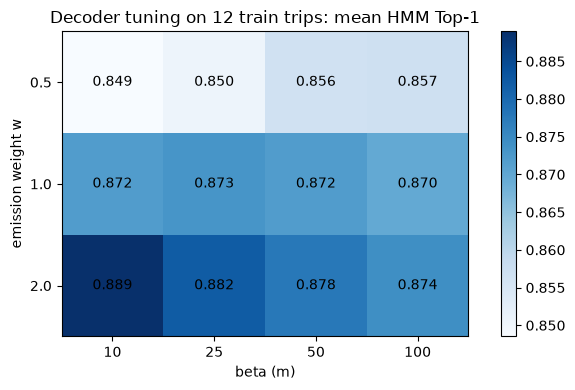

In [2]:
tune_trips = list_trips('train')[::7][:12]
preds = {}
grid = []
for beta, w in itertools.product([10, 25, 50, 100], [0.5, 1.0, 2.0]):
    accs = []
    for tid in tune_trips:
        trip = load_trip('train', tid, with_route=False)
        p = predict_trip(trip, model, dict(beta=beta, w_emit=w, unreachable=-20.0))
        accs.append(score_trip('train', tid, p)['hmm_top1_accuracy'])
    grid.append(dict(beta=beta, w_emit=w, mean_top1=np.nanmean(accs)))
    print(grid[-1])
grid = pd.DataFrame(grid); grid.to_csv(f'{OUT}/decoder_grid_train.csv', index=False)
best = grid.loc[grid.mean_top1.idxmax()]
HMM = dict(beta=float(best.beta), w_emit=float(best.w_emit), unreachable=-20.0)
json.dump(HMM, open('../models/hmm_config.json', 'w'), indent=2); print('chosen decoder parameters:', HMM)
pv = grid.pivot(index='w_emit', columns='beta', values='mean_top1')
fig, ax = plt.subplots(figsize=(7,4)); im = ax.imshow(pv.values, cmap='Blues')
ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns); ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]): ax.text(j, i, f'{pv.values[i,j]:.3f}', ha='center', va='center')
ax.set_title('Decoder tuning on 12 train trips: mean HMM Top-1'); ax.set_xlabel('beta (m)'); ax.set_ylabel('emission weight w')
plt.colorbar(im); plt.tight_layout(); plt.savefig(f'{OUT}/decoder_grid.png'); plt.show()

### Classifier-only vs classifier + HMM on student-test

In [3]:
rows, store = [], {}
for tid in list_trips('student_test'):
    trip = load_trip('student_test', tid, with_route=False)
    p = predict_trip(trip, model, HMM); s = score_trip('student_test', tid, p)
    store[tid] = p
    rows.append(dict(trip_id=tid, n_points=s['n_points'], clf_top1=s['clf_top1_accuracy'], hmm_top1=s['hmm_top1_accuracy'],
                     clf_continuity=s['clf_route_continuity'], hmm_continuity=s['hmm_route_continuity'],
                     clf_route_f1=s['clf_route_f1'], hmm_route_f1=s['hmm_route_f1'],
                     hmm_time_s=p['timing_s']['hmm_viterbi']))
cmpd = pd.DataFrame(rows); cmpd['top1_change'] = cmpd.hmm_top1 - cmpd.clf_top1
w = cmpd.n_points / cmpd.n_points.sum()
summary = pd.DataFrame({'classifier_only': [(cmpd.clf_top1*w).sum(), (cmpd.clf_continuity*w).sum(), cmpd.clf_route_f1.mean()],
                        'classifier_plus_hmm': [(cmpd.hmm_top1*w).sum(), (cmpd.hmm_continuity*w).sum(), cmpd.hmm_route_f1.mean()]},
                       index=['Top-1 accuracy (point-weighted)', 'Route continuity (point-weighted)', 'Route F1, length-weighted (mean over trips) - sequence level'])
cmpd.to_csv(f'{OUT}/student_test_hmm_vs_classifier.csv', index=False); summary.to_csv(f'{OUT}/hmm_summary.csv')
display(summary.round(4)); cmpd.round(4)

,classifier_only,classifier_plus_hmm
Top-1 accuracy (point-weighted),0.8713,0.8975
Route continuity (point-weighted),0.9355,0.9780
"Route F1, length-weighted (mean over trips) - sequence level",0.9333,0.9643


,trip_id,n_points,clf_top1,hmm_top1,clf_continuity,hmm_continuity,clf_route_f1,hmm_route_f1,hmm_time_s,top1_change
0,00000000,2503,0.9469,0.9565,0.9712,0.9944,0.9793,0.9929,0.3522,0.0096
1,00000007,1354,0.9180,0.9357,0.9978,1.0000,0.9856,0.9872,0.1020,0.0177
2,00000009,1049,0.8818,0.9085,0.8941,0.9475,0.9052,0.9329,0.2820,0.0267
3,00000040,2995,0.9316,0.9422,0.9656,0.9950,0.9635,0.9907,0.4297,0.0107
4,00000052,262,0.9733,0.9847,0.9502,0.9617,0.9541,0.9772,0.0556,0.0115
5,00000056,3958,0.9135,0.9555,0.9098,0.9646,0.9202,0.9721,0.8575,0.0420
6,00000065,768,0.8424,0.8646,0.9439,0.9791,0.9119,0.9710,0.1899,0.0221
7,00000076,1486,0.9125,0.9314,0.8963,0.9589,0.9196,0.9419,0.4536,0.0188
8,00000077,3911,0.6952,0.7359,0.9271,0.9811,0.8532,0.9048,0.8010,0.0407
9,00000091,874,0.8844,0.9085,0.8912,0.9576,0.9402,0.9722,0.1668,0.0240


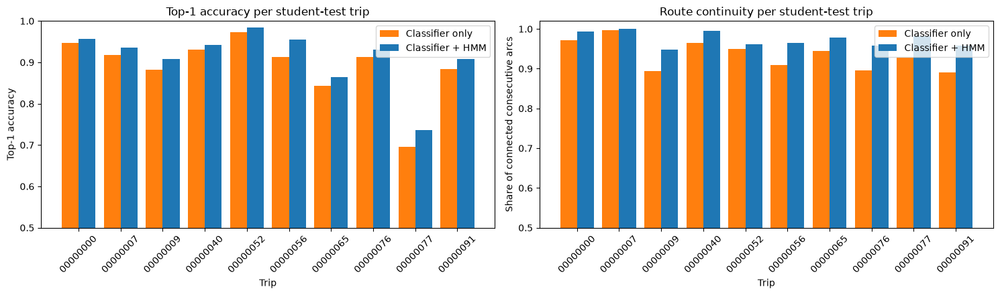

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5)); x = np.arange(len(cmpd))
ax[0].bar(x-0.2, cmpd.clf_top1, 0.4, label='Classifier only', color='tab:orange')
ax[0].bar(x+0.2, cmpd.hmm_top1, 0.4, label='Classifier + HMM', color='tab:blue')
ax[0].set_xticks(x); ax[0].set_xticklabels(cmpd.trip_id, rotation=45); ax[0].set_ylim(0.5, 1.0)
ax[0].set_title('Top-1 accuracy per student-test trip'); ax[0].set_xlabel('Trip'); ax[0].set_ylabel('Top-1 accuracy'); ax[0].legend()
ax[1].bar(x-0.2, cmpd.clf_continuity, 0.4, label='Classifier only', color='tab:orange')
ax[1].bar(x+0.2, cmpd.hmm_continuity, 0.4, label='Classifier + HMM', color='tab:blue')
ax[1].set_xticks(x); ax[1].set_xticklabels(cmpd.trip_id, rotation=45); ax[1].set_ylim(0.5, 1.02)
ax[1].set_title('Route continuity per student-test trip'); ax[1].set_xlabel('Trip'); ax[1].set_ylabel('Share of connected consecutive arcs'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/hmm_vs_classifier.png'); plt.show()

### Sequence-level performance: length-weighted route F1 per trip

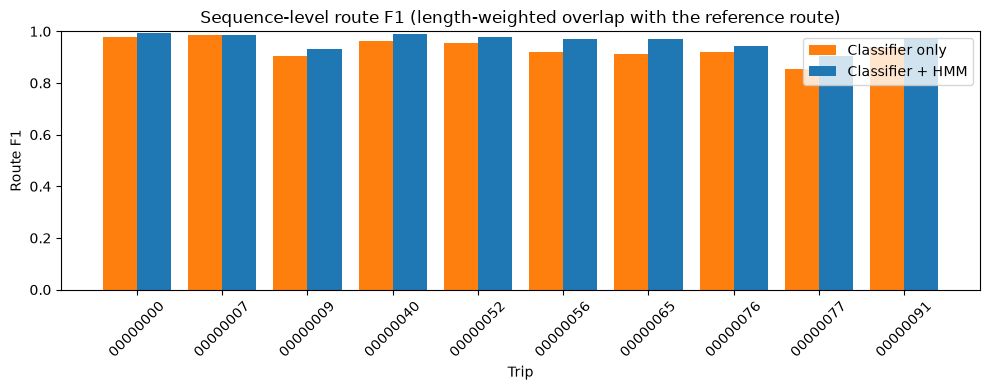

In [5]:
fig, ax = plt.subplots(figsize=(10, 4)); x = np.arange(len(cmpd))
ax.bar(x-0.2, cmpd.clf_route_f1, 0.4, label='Classifier only', color='tab:orange')
ax.bar(x+0.2, cmpd.hmm_route_f1, 0.4, label='Classifier + HMM', color='tab:blue')
ax.set_xticks(x); ax.set_xticklabels(cmpd.trip_id, rotation=45); ax.set_ylim(0.0, 1.0)
ax.set_title('Sequence-level route F1 (length-weighted overlap with the reference route)'); ax.set_xlabel('Trip'); ax.set_ylabel('Route F1'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/route_f1_per_trip.png'); plt.show()

### Folium maps: GPS, road network, reference, classifier-only and HMM routes

In [6]:
def arcs_layer(name, arc_ids, nodes, arcs, color, weight, show=True):
    g = folium.FeatureGroup(name, show=show)
    for a in pd.unique(np.asarray(arc_ids)[np.asarray(arc_ids) >= 0]):
        u, v = arcs[a]; folium.PolyLine([(nodes[u,1], nodes[u,0]), (nodes[v,1], nodes[v,0])], color=color, weight=weight, opacity=.8).add_to(g)
    return g

def compare_map(tid):
    ref = load_trip('student_test', tid); p = store[tid]
    t = ref['track']; nodes = ref['nodes'].values; arcs = ref['arcs'].values
    m = folium.Map(location=[t.lat.mean(), t.lon.mean()], zoom_start=14, tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}', attr='Tiles &copy; Esri')
    lo, la = t.lon.agg(['min','max']), t.lat.agg(['min','max'])
    nm = ((nodes[arcs[:,0],0] > lo['min']-.003) & (nodes[arcs[:,0],0] < lo['max']+.003) & (nodes[arcs[:,0],1] > la['min']-.003) & (nodes[arcs[:,0],1] < la['max']+.003))
    arcs_layer('Road network (grey)', np.where(nm)[0], nodes, arcs, 'grey', 1, show=False).add_to(m)
    arcs_layer('Reference route (green)', ref['route'], nodes, arcs, 'green', 7).add_to(m)
    arcs_layer('Classifier-only (orange)', p['clf_arcs'], nodes, arcs, 'orange', 4, show=False).add_to(m)
    arcs_layer('Classifier + HMM (red)', p['hmm_arcs'], nodes, arcs, 'red', 3).add_to(m)
    g = folium.FeatureGroup('GPS points (blue)')
    for k, r in t.iloc[::2].iterrows(): folium.CircleMarker([r.lat, r.lon], radius=2, color='blue', fill=True, popup=f'point {k}').add_to(g)
    g.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m); m.fit_bounds([[la['min'], lo['min']], [la['max'], lo['max']]])
    m.save(f'{MAPS}/05_student_test_{tid}_hmm_vs_classifier.html'); return m

best_gain = cmpd.sort_values('top1_change').trip_id.iloc[-1]; worst = cmpd.sort_values('top1_change').trip_id.iloc[0]
print('largest HMM gain:', best_gain, ' | HMM did not help most:', worst)
compare_map(best_gain)

largest HMM gain: 00000056  | HMM did not help most: 00000000


In [7]:
compare_map(worst)